# 16 · Views over time: forecast from the first check and estimate at posting time

Second Brand24 file `reach_samples_students_with_history.csv`: the same 12,500 mentions plus up to three earlier checks (`history_1..3_*`) and the latest check (`current_*`). Two questions:
1. Given the first check of a post (views and reactions a few hours or days after posting), how well can the views at a later check be forecast?
2. Before any reaction exists (at posting time), how well can views be estimated from followers, text and time?

Validation as in the other notebooks: 5-fold CV grouped by brand, MAE of log10(views), brand bootstrap CI.

In [1]:
import sys, json, warnings; warnings.filterwarnings("ignore")
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data" / "raw" / "reach_samples_students.csv").exists())
sys.path.insert(0, str(ROOT / "src"))
import eda_utils as eu, history as H

FIG = ROOT / "figures"; plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.width", 220, "display.max_columns", 30)
CB = "CatBoost: first check + reactions + ages"; PT = "CatBoost: posting-time columns"

In [2]:
d = H.load(ROOT); s = H.snapshots(d); p = H.pairs(s)

## 1 · The new columns
Only the new columns are shown (no author or URL columns; `attributes_url` is left out).

In [3]:
new = [c for c in d.columns if c.startswith(("attributes_", "current_", "history_")) and c != "attributes_url"]
d[["platform", "created_at", "metrics_updated_at", "view_count"] + new].dropna(subset=["history_1_at"]).head()

,platform,created_at,metrics_updated_at,view_count,attributes_found,attributes_last_update,current_likes,current_comments,current_shares,current_views,history_count,history_1_at,history_1_likes,history_1_comments,history_1_shares,history_1_views,history_2_at,history_2_likes,history_2_comments,history_2_shares,history_2_views,history_3_at,history_3_likes,history_3_comments,history_3_shares,history_3_views
56,twitter,2026-08-23 23:52:56,2026-08-24 10:27:22,6.0,1,2026-08-24 10:27:22,0.0,0.0,0.0,6.0,3,2026-08-24 08:05:52,0.0,0.0,0.0,2.0,2026-08-24 08:08:17,0.0,0.0,0.0,2.0,2026-08-24 08:14:52,0.0,0.0,0.0,2.0
57,twitter,2026-08-23 23:49:09,2026-08-24 10:27:22,9.0,1,2026-08-24 10:27:22,0.0,4.0,0.0,9.0,3,2026-08-24 07:05:47,0.0,2.0,0.0,1.0,2026-08-24 07:08:13,0.0,2.0,0.0,1.0,2026-08-24 07:14:41,0.0,2.0,0.0,1.0
58,twitter,2026-08-23 23:39:41,2026-08-24 23:29:18,9.0,1,2026-08-24 17:46:39,0.0,2.0,0.0,9.0,3,2026-08-24 07:05:47,0.0,1.0,0.0,2.0,2026-08-24 07:08:13,0.0,1.0,0.0,2.0,2026-08-24 07:14:41,0.0,2.0,0.0,4.0
59,twitter,2026-08-23 23:29:16,2026-08-24 10:12:44,296.0,1,2026-08-24 10:09:03,12.0,0.0,11.0,296.0,3,2026-08-24 07:05:47,6.0,0.0,5.0,125.0,2026-08-24 07:08:13,6.0,0.0,5.0,131.0,2026-08-24 07:14:41,7.0,0.0,6.0,142.0
60,twitter,2026-08-23 23:21:34,2026-08-24 23:23:24,10874.0,1,2026-08-24 12:55:37,5.0,3.0,0.0,10874.0,3,2026-08-24 07:05:47,0.0,0.0,0.0,702.0,2026-08-24 07:08:13,0.0,0.0,0.0,758.0,2026-08-24 07:14:41,0.0,0.0,0.0,955.0


In [4]:
cov = d.groupby("platform").agg(mentions=("mention_id", "size"), attributes_found=("attributes_found", "sum"), current_views=("current_views", lambda x: x.notna().sum()),
                                history_1=("history_1_views", lambda x: x.notna().sum()), history_2=("history_2_views", lambda x: x.notna().sum()), history_3=("history_3_views", lambda x: x.notna().sum()))
cov.loc["TOTAL"] = cov.sum(); cov

,mentions,attributes_found,current_views,history_1,history_2,history_3
platform,,,,,,
facebook,2500,0,0,0,0,0
instagram,2500,4,0,0,0,0
tiktok,2500,350,350,341,328,289
twitter,2500,364,364,349,225,152
youtube,2500,512,511,0,0,0
TOTAL,12500,1230,1225,690,553,441


Checks per mention after merging main, history and current values (duplicates of the same time and views dropped), and the pairs used below (first and last check, at least 1 h apart).

In [5]:
n = s.groupby("mention_id").size().rename("checks"); t = pd.crosstab(s.drop_duplicates("mention_id").set_index("mention_id").platform, n); t.loc["TOTAL"] = t.sum(); t

checks,1,2,3,4,5
platform,,,,,
tiktok,2158,28,49,160,105
twitter,1532,100,100,99,45
youtube,2175,301,0,0,0
TOTAL,5865,429,149,259,150


In [6]:
A = p.groupby("platform")[["age_h", "age_h_end"]].median().assign(posts=p.groupby("platform").size(), month=p.groupby("platform").created_at.median().dt.strftime("%Y-%m"))
A.loc["TOTAL"] = [p.age_h.median(), p.age_h_end.median(), len(p), p.created_at.median().strftime("%Y-%m")]; A.rename(columns={"age_h": "median age first check (h)", "age_h_end": "median age last check (h)"})

,median age first check (h),median age last check (h),posts,month
platform,,,,
tiktok,30.067361,222.173611,336,2026-08
twitter,7.488333,13.723611,331,2026-08
youtube,102.475556,706.265833,289,2026-08
TOTAL,22.158750,191.170972,956,2026-08


Check: views never fall between checks of a post, and the age of the main check in the full file (for comparison with the history subset).

In [7]:
print("views non-decreasing:", s.groupby("mention_id").views.apply(lambda v: v.is_monotonic_increasing).mean())
d.assign(age_main_h=(d.metrics_updated_at - d.created_at).dt.total_seconds() / 3600)[d.view_count.notna()].groupby("platform").age_main_h.median().rename("median age of main check, full file (h)")

views non-decreasing: 0.9986865148861647


platform
tiktok     858.249167
twitter    533.770278
youtube    600.541389
Name: median age of main check, full file (h), dtype: float64

## 2 · Growth between checks

In [8]:
B = H.growth_exponent(p); B.round(3)

,platform,posts,b,CI low,CI high,median growth x,median age first (h),median age last (h)
0,tiktok,336,0.346,0.294,0.392,1.345,30.067,222.174
1,twitter,331,1.170,0.756,1.932,2.385,7.488,13.724
2,youtube,289,0.579,0.503,0.657,1.235,102.476,706.266


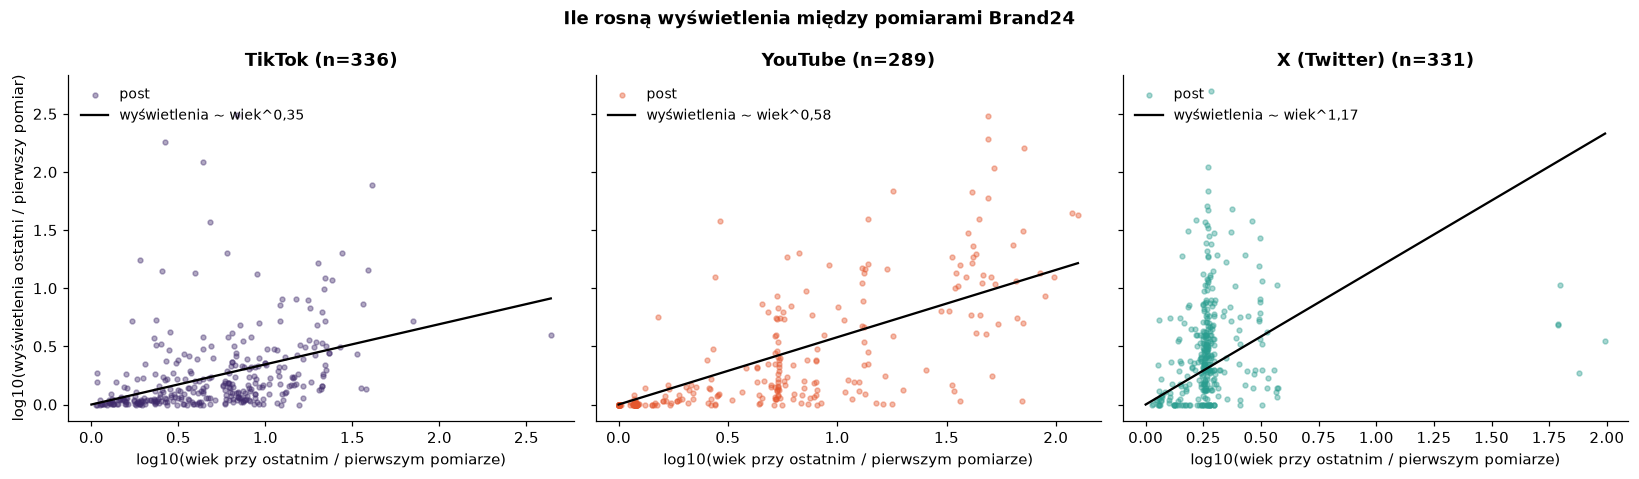

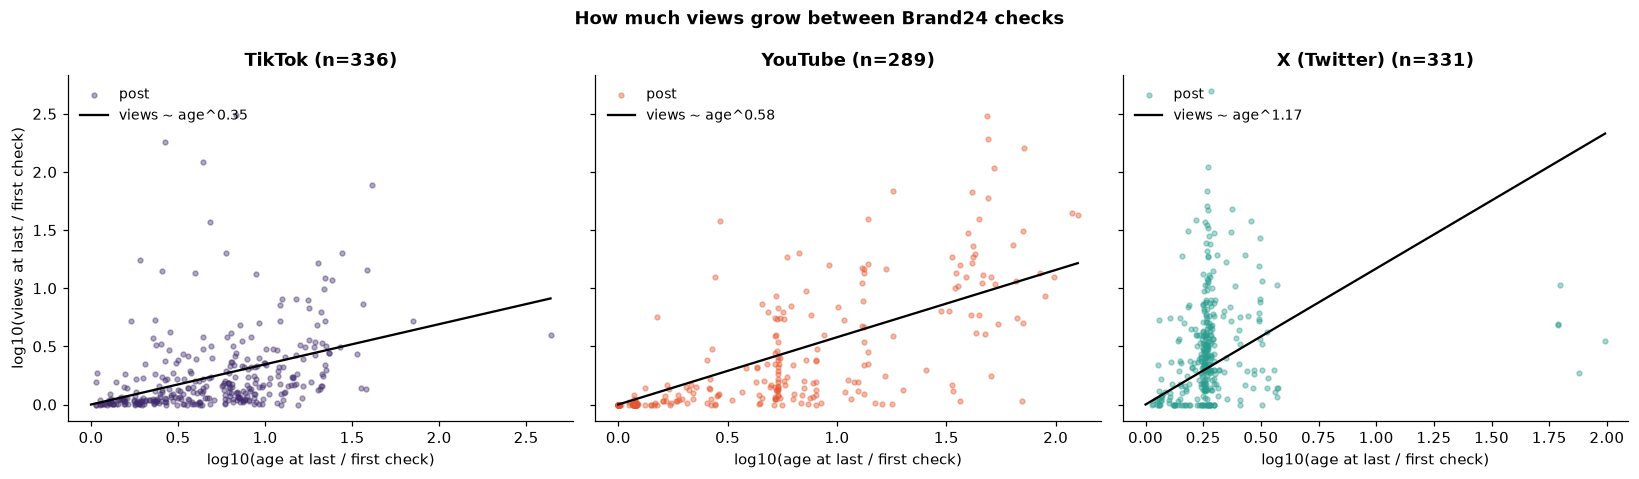

In [9]:
for l in ("pl", "en"): H.plot_growth(p, B, FIG / f"history_growth_{l}.png", l)

## 3 · Forecast of the last check from the first check

In [10]:
P = H.forecast_cv(p); TF = H.summarise(P); TF.round(3)

,platform,model,posts,MAE,CI low,CI high,bias
0,tiktok,first check as-is (persistence),336,0.248,0.209,0.287,-0.248
1,tiktok,first check x median growth,336,0.208,0.174,0.239,-0.122
2,tiktok,first check x power law in age,336,0.194,0.167,0.224,-0.005
3,tiktok,CatBoost: first check + reactions + ages,336,0.165,0.133,0.195,-0.056
4,tiktok,CatBoost without first-check views (reactions ...,336,0.368,0.330,0.405,-0.036
5,twitter,first check as-is (persistence),331,0.481,0.418,0.547,-0.481
6,twitter,first check x median growth,331,0.324,0.289,0.357,-0.102
7,twitter,first check x power law in age,331,0.345,0.282,0.430,-0.121
8,twitter,CatBoost: first check + reactions + ages,331,0.269,0.236,0.295,-0.047
9,twitter,CatBoost without first-check views (reactions ...,331,0.544,0.485,0.597,-0.077


In [11]:
G1 = pd.DataFrame([{"platform": pl, "comparison": f"{b} -> {CB}", **dict(zip(["gain", "CI low", "CI high"], H.gain_ci(P, pl, b, CB)))}
                   for pl in H.PLATS for b in ["first check as-is (persistence)", "first check x power law in age", "CatBoost without first-check views (reactions only)"]]); G1.round(3)

,platform,comparison,gain,CI low,CI high
0,tiktok,first check as-is (persistence) -> CatBoost: f...,0.083,0.059,0.112
1,tiktok,first check x power law in age -> CatBoost: fi...,0.029,0.013,0.046
2,tiktok,CatBoost without first-check views (reactions ...,0.203,0.170,0.237
3,youtube,first check as-is (persistence) -> CatBoost: f...,0.165,0.111,0.228
4,youtube,first check x power law in age -> CatBoost: fi...,0.045,0.014,0.077
5,youtube,CatBoost without first-check views (reactions ...,0.256,0.207,0.300
6,twitter,first check as-is (persistence) -> CatBoost: f...,0.212,0.154,0.265
7,twitter,first check x power law in age -> CatBoost: fi...,0.076,0.020,0.163
8,twitter,CatBoost without first-check views (reactions ...,0.275,0.227,0.317


In [12]:
IF = H.oof_intervals(P, CB); IF.round(3)

,platform,coverage,half width log10,factor x
0,tiktok,0.902,0.372,2.355
1,twitter,0.903,0.614,4.113
2,youtube,0.903,0.581,3.809


In [13]:
HZ = H.by_horizon(P, CB); HZ.round(3)

,platform,h,posts,MAE
0,tiktok,<12h,12.0,0.117
1,tiktok,12-48h,29.0,0.129
2,tiktok,2-7d,87.0,0.161
3,tiktok,7-30d,203.0,0.175
4,tiktok,>30d,5.0,0.157
5,twitter,<12h,292.0,0.269
6,twitter,12-48h,33.0,0.289
7,twitter,7-30d,6.0,0.157
8,youtube,<12h,37.0,0.035
9,youtube,12-48h,8.0,0.165


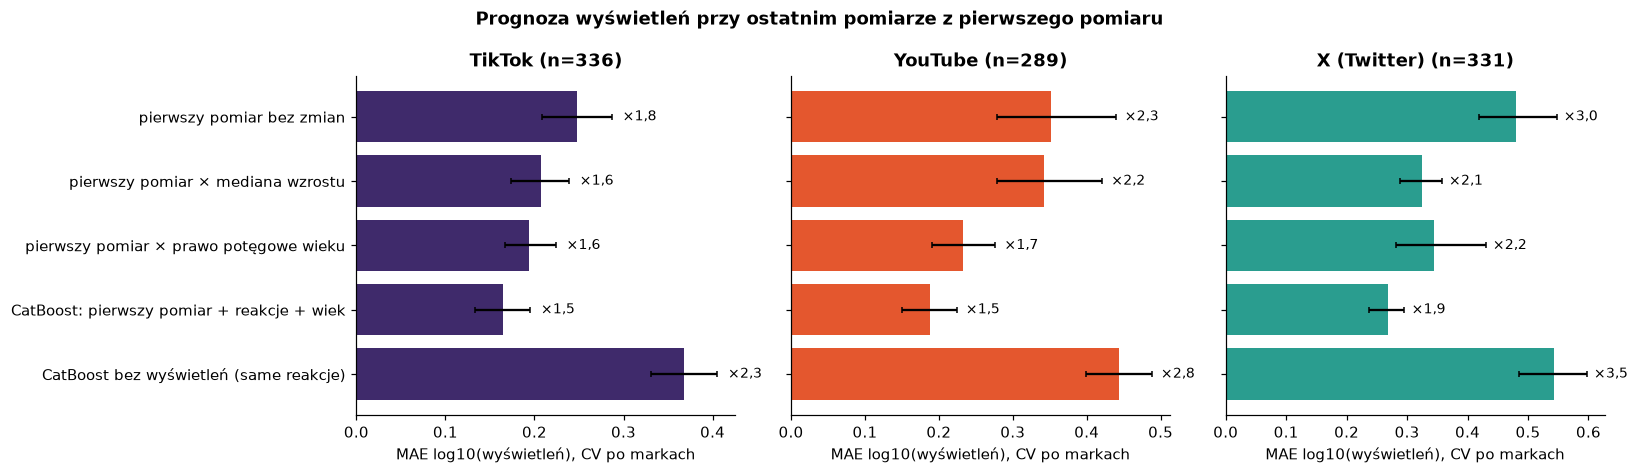

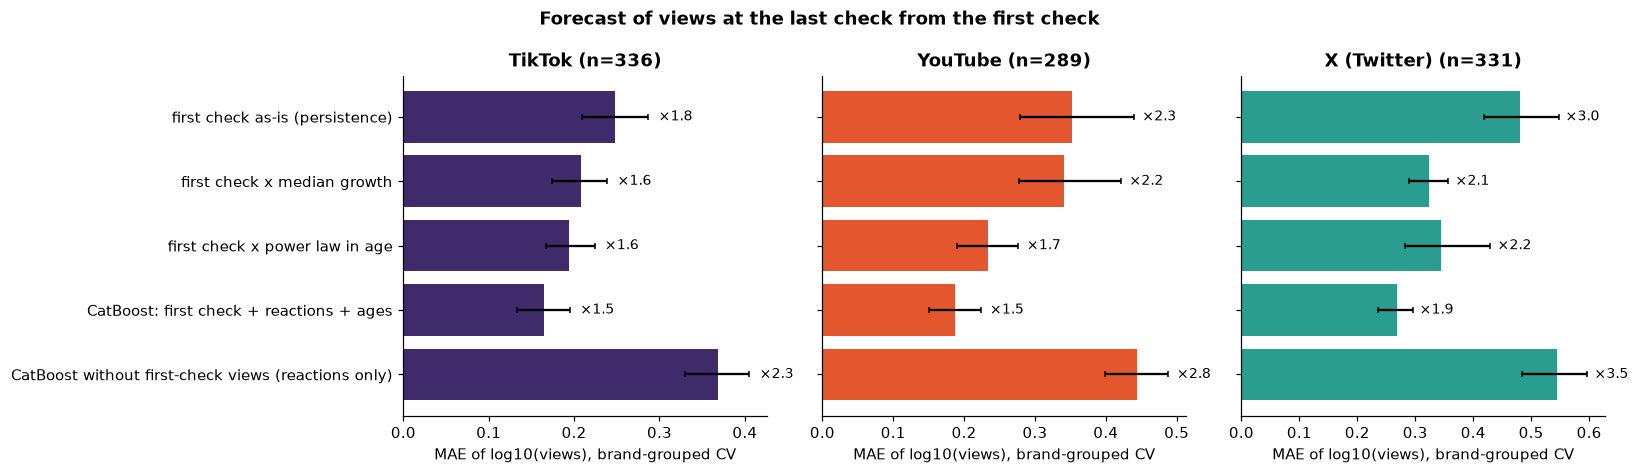

In [14]:
for l in ("pl", "en"): H.plot_mae(TF, "Prognoza wyświetleń przy ostatnim pomiarze z pierwszego pomiaru" if l == "pl" else "Forecast of views at the last check from the first check", FIG / f"history_forecast_{l}.png", l)

## 4 · Estimate at posting time (no reactions)
All TikTok / YouTube / X mentions with views. Posting-time columns: followers, text statistics, VADER, TF-IDF SVD, AI labels, calendar, brand size, and the horizon (hours from posting to the check, which a user would choose). Author history: smoothed mean views of the same author in the training fold.

In [15]:
GR, meta = H.posting_time_data(ROOT)
Q = pd.concat([H.posting_time_cv(GR, meta, pl) for pl in H.PLATS], ignore_index=True); TP = H.summarise(Q); TP.round(3)

,platform,model,posts,MAE,CI low,CI high,bias
0,tiktok,median views,2491,0.663,0.634,0.691,-0.170
1,tiktok,constant x followers,2491,0.912,0.881,0.944,-0.082
2,tiktok,CatBoost: followers,2491,0.591,0.564,0.617,-0.110
3,tiktok,CatBoost: posting-time columns,2491,0.575,0.550,0.600,-0.100
4,tiktok,CatBoost: posting-time + author history,2491,0.573,0.548,0.597,-0.091
5,tiktok,reference: posting-time + reactions,2491,0.272,0.261,0.283,-0.017
6,youtube,median views,2441,0.944,0.910,0.978,0.009
7,youtube,constant x followers,2441,0.860,0.825,0.899,0.044
8,youtube,CatBoost: followers,2441,0.775,0.749,0.803,0.034
9,youtube,CatBoost: posting-time columns,2441,0.684,0.659,0.706,-0.009


In [16]:
G2 = pd.DataFrame([{"platform": pl, "comparison": f"{a} -> {b}", **dict(zip(["gain", "CI low", "CI high"], H.gain_ci(Q, pl, a, b)))}
                   for pl in H.PLATS for a, b in [("constant x followers", PT), ("CatBoost: followers", PT), (PT, "CatBoost: posting-time + author history")]]); G2.round(3)

,platform,comparison,gain,CI low,CI high
0,tiktok,constant x followers -> CatBoost: posting-time...,0.337,0.307,0.365
1,tiktok,CatBoost: followers -> CatBoost: posting-time ...,0.017,0.007,0.025
2,tiktok,CatBoost: posting-time columns -> CatBoost: po...,0.001,-0.002,0.005
3,youtube,constant x followers -> CatBoost: posting-time...,0.176,0.147,0.209
4,youtube,CatBoost: followers -> CatBoost: posting-time ...,0.092,0.072,0.113
5,youtube,CatBoost: posting-time columns -> CatBoost: po...,-0.002,-0.010,0.006
6,twitter,constant x followers -> CatBoost: posting-time...,0.330,0.288,0.372
7,twitter,CatBoost: followers -> CatBoost: posting-time ...,0.034,0.019,0.050
8,twitter,CatBoost: posting-time columns -> CatBoost: po...,0.004,-0.001,0.010


In [17]:
IP = H.oof_intervals(Q, PT); IP.round(3)

,platform,coverage,half width log10,factor x
0,tiktok,0.9,1.291,19.531
1,twitter,0.9,1.156,14.309
2,youtube,0.9,1.438,27.406


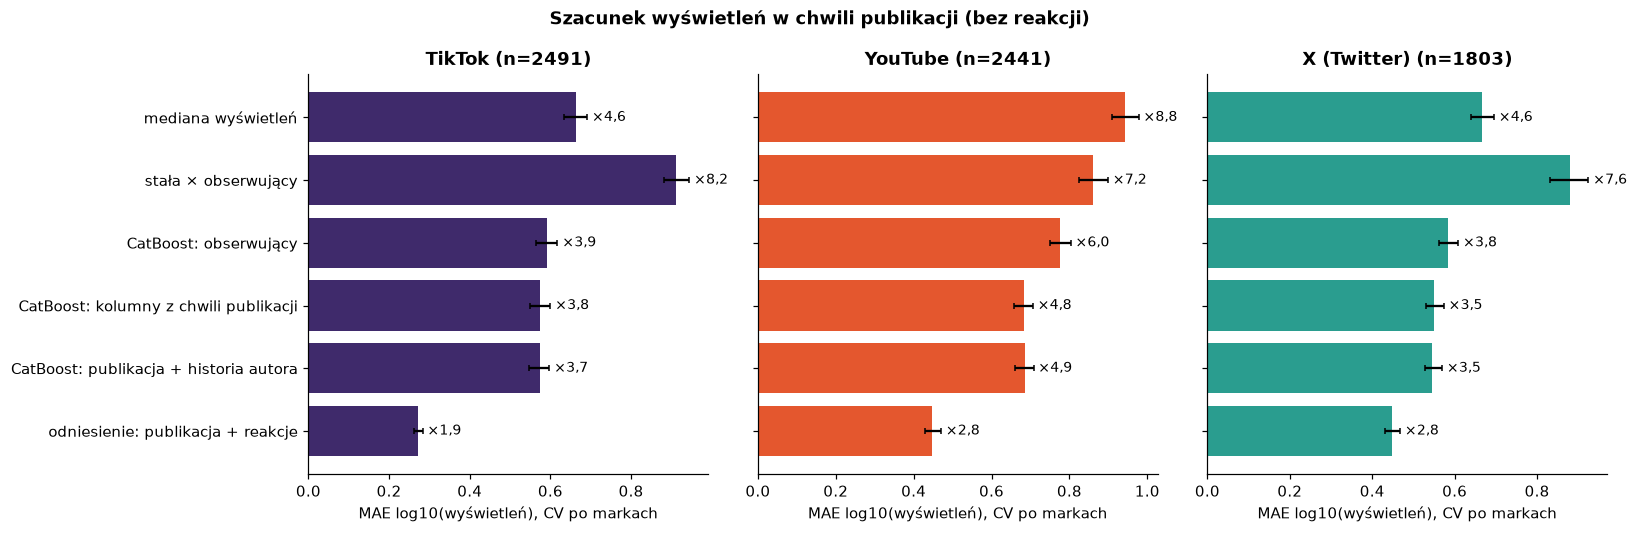

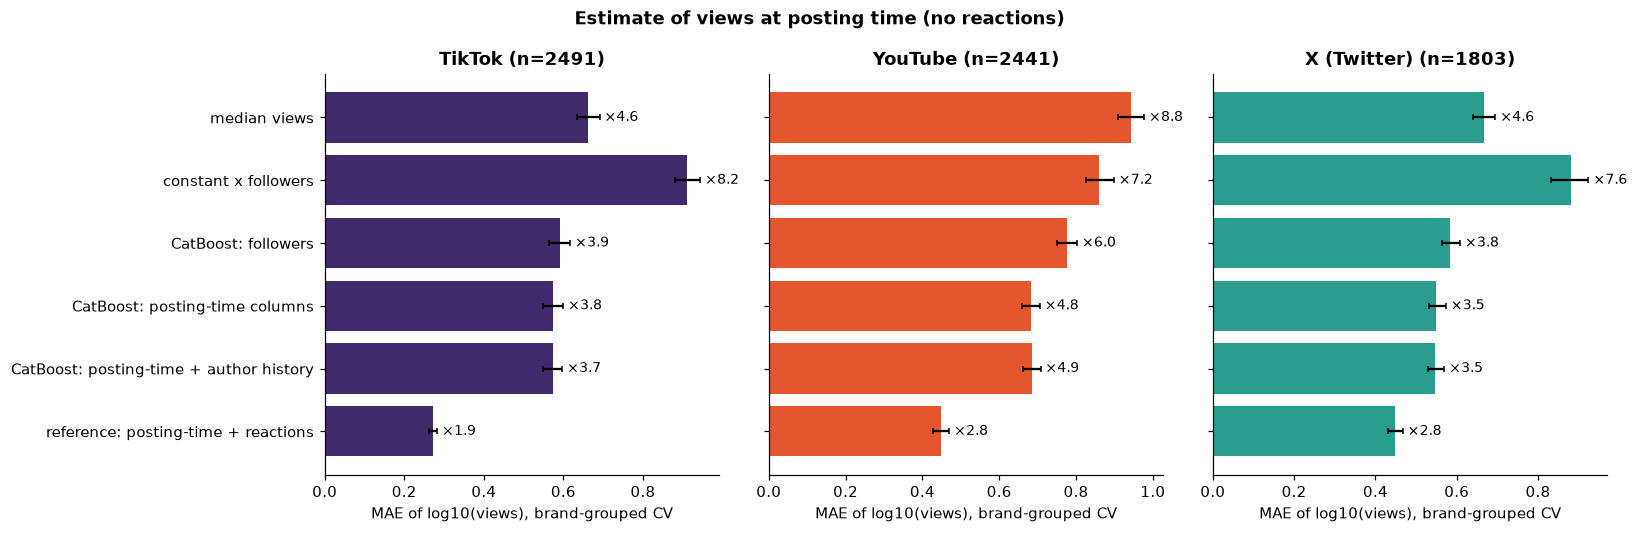

In [18]:
for l in ("pl", "en"): H.plot_mae(TP, "Szacunek wyświetleń w chwili publikacji (bez reakcji)" if l == "pl" else "Estimate of views at posting time (no reactions)", FIG / f"history_posting_{l}.png", l)

## Takeaways
See `docs/en/experiments.md` (E38-E43). Numbers: `data/processed/history_numbers.json`.

In [19]:
json.dump({"coverage": cov.reset_index().to_dict("records"), "growth": B.to_dict("records"), "forecast": TF.to_dict("records"), "forecast_gains": G1.to_dict("records"),
           "forecast_intervals": IF.to_dict("records"), "forecast_by_horizon": HZ.astype({"h": str}).to_dict("records"), "posting": TP.to_dict("records"),
           "posting_gains": G2.to_dict("records"), "posting_intervals": IP.to_dict("records")},
          open(ROOT / "data" / "processed" / "history_numbers.json", "w"), indent=1, default=float)